In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv("/Users/macbookair/Desktop/Customer-Churn-Prediction/data/Telco-Customer-Churn.csv")

In [3]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
data.shape

(7043, 21)

In [5]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
data.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:
data['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

# Task 2A — Investigate TotalCharges

In [11]:
data['TotalCharges'].unique()[:20]


array(['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5',
       '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8',
       '5681.1', '5036.3', '2686.05', '7895.15', '1022.95', '7382.25',
       '528.35', '1862.9'], dtype=object)

In [12]:
print("Blank values: ",
      (data["TotalCharges"].str.strip() == "").sum())

Blank values:  11


In [13]:
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

In [14]:
data["TotalCharges"].isnull().sum()

np.int64(11)

With errors='coerce': Pandas forces the conversion, turns the bad/invalid entries into NaN  

and same missing values apear after conversion

# Task 2B — Visualize the churn distribution

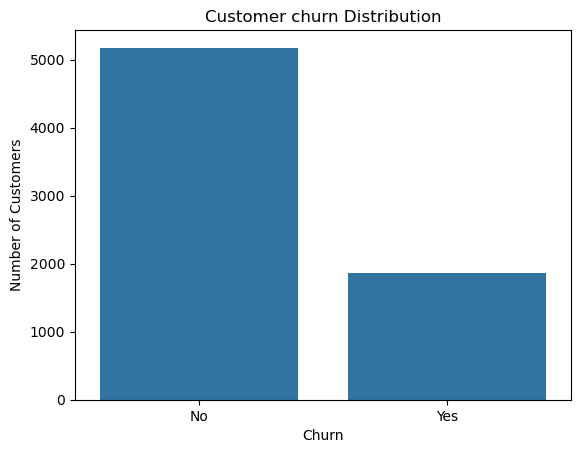

In [15]:
import seaborn as sns

sns.countplot(data=data, x = "Churn")

plt.title("Customer churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [16]:
print(
    (data["Churn"].value_counts(normalize=True)*100).round(2)
)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


1. Is the dataset balanced or imbalanced?
=> the dataset is imbalanced
2. If a model predicts No for every customer, what accuracy will it achieve?
=> 73.46
3. Why could that accuracy be misleading for a churn-prediction business?
=> the model has 0% recall for churned customers. It fails to identify every customer who leaves and if I mark all the customer to "NO" we will lose a huge amount of customer without knowing

# Task 3: Discover why customers churn

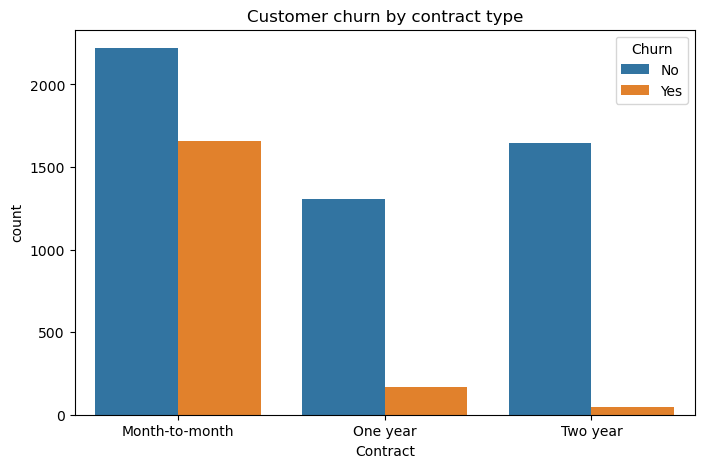

In [17]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=data,
    x = "Contract",
    hue = "Churn"
)

plt.title("Customer churn by contract type")
plt.show()

In [18]:
contract_churn = pd.crosstab(
    data["Contract"],
    data["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


1. Which contract type has the highest churn rate? Why might customers with month-to-month contracts be more likely to leave?

=> month-to-month contract type has the highest churn rate 
=> ig it is about the duration or habit

Analyze churn by customer tenure


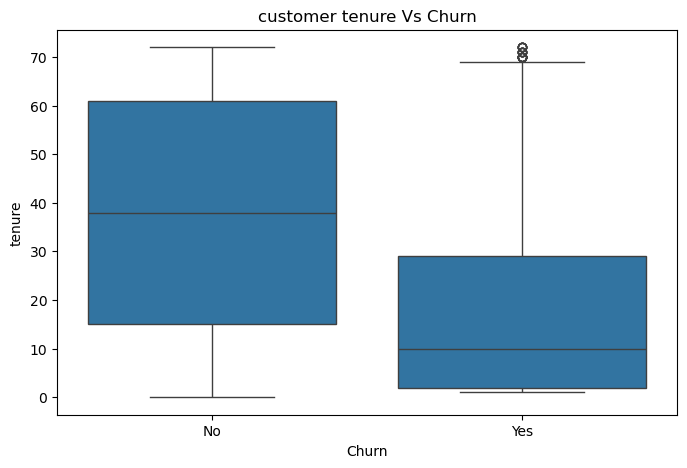

In [19]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=data,
    x = "Churn",
    y = "tenure"
)

plt.title("customer tenure Vs Churn")
plt.show()

In [20]:
print(
    data.groupby("Churn")["tenure"].agg(
        ["mean", "median"]
    ).round(2)
)

        mean  median
Churn               
No     37.57    38.0
Yes    17.98    10.0


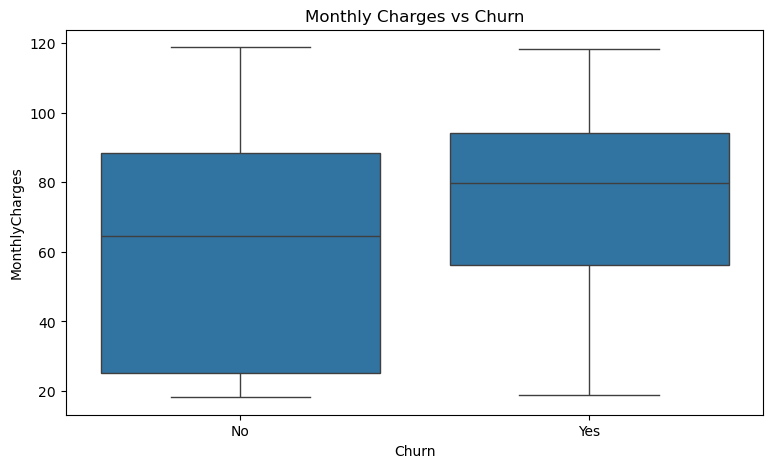

In [21]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")
plt.show()

In [22]:
print(
    data.groupby("Churn")["MonthlyCharges"].agg(
        ["mean", "median"]
    ).round(2)
)

        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


1. Your interpretation of the three findings.

=> one or two year contarct is good for customer retaining. more tenure less customer churn . more monthly charge more churn

In [23]:
# Churn rate by contract type
print(
    data.groupby("Contract", observed=True)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .round(2)
)

# Churn rate by tenure group
data["TenureGroup"] = pd.cut(
    data["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

print(
    data.groupby("TenureGroup", observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .round(2)
)

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64
TenureGroup
0-12     47.44
13-24    28.71
25-48    20.39
49-72     9.51
Name: Churn, dtype: float64


# data quality

1. convert total charges into numeric

In [24]:
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

In [25]:
data.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
TenureGroup          0
dtype: int64

In [26]:
data["TotalCharges"].fillna(data["TotalCharges"].median(), inplace=True)

/var/folders/4g/9m2h6m6x0lxbsngvlhdmn_dm0000gn/T/ipykernel_90410/3567840028.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data["TotalCharges"].fillna(data["TotalCharges"].median(), inplace=True)


In [27]:
data.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
TenureGroup         0
dtype: int64

In [28]:
data.dtypes

customerID            object
gender                object
SeniorCitizen          int64
Partner               object
Dependents            object
tenure                 int64
PhoneService          object
MultipleLines         object
InternetService       object
OnlineSecurity        object
OnlineBackup          object
DeviceProtection      object
TechSupport           object
StreamingTV           object
StreamingMovies       object
Contract              object
PaperlessBilling      object
PaymentMethod         object
MonthlyCharges       float64
TotalCharges         float64
Churn                 object
TenureGroup         category
dtype: object

# Choosing feature

In [29]:
y = data["Churn"].map({"No": 0, "Yes": 1})


In [30]:
X = data.drop(columns=["Churn", "customerID","TenureGroup"])

In [31]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

In [32]:
categorical_features = [
    col for col in X.columns
    if col not in numerical_features
]

In [33]:
# 5. Inspect the selected features
print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)

# 6. Check for missing values
print("\nMissing values:")
print(X.isnull().sum()[X.isnull().sum() > 0])

Numerical features:
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Feature matrix shape: (7043, 19)
Target shape: (7043,)

Missing values:
Series([], dtype: int64)


# Train/Test Split.

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test,y_train, y_test = train_test_split(X,y , random_state=42, test_size=0.2, stratify=y)

In [35]:
# Check the shapes
print("Original dataset:", X.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check churn distribution
print("\nTraining churn rate:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting churn rate:")
print((y_test.value_counts(normalize=True) * 100).round(2))

# Check missing values
print("\nMissing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Original dataset: (7043, 19)
Training features: (5634, 19)
Testing features: (1409, 19)

Training target: (5634,)
Testing target: (1409,)

Training churn rate:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Testing churn rate:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Missing values in training data: 0
Missing values in testing data: 0


# preprocessing

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


In [37]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())

])

In [38]:
categorical_Pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [39]:
preprocessor = ColumnTransformer([
    ("numeric", numerical_pipeline, numerical_features),
    ("categorical", categorical_Pipeline, categorical_features)
])

In [40]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5634, 46)
Processed testing shape: (1409, 46)


In [41]:
from scipy import sparse

if sparse.issparse(X_train_processed):
    print("Training NaN:", np.isnan(X_train_processed.data).sum())
    print("Testing NaN:", np.isnan(X_test_processed.data).sum())
else:
    print("Training NaN:", np.isnan(X_train_processed).sum())
    print("Testing NaN:", np.isnan(X_test_processed).sum())

Training NaN: 0
Testing NaN: 0


# Model Training


In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [44]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


# Model Evaluation

In [45]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, pipeline in trained_models.items():
    
    y_pred = pipeline.predict(X_test)

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.set_index("Model").round(4)

results_df

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
Decision Tree,0.7303,0.4923,0.5107,0.5013,0.6599
Random Forest,0.7814,0.6138,0.4759,0.5361,0.8167


# confusion matrix


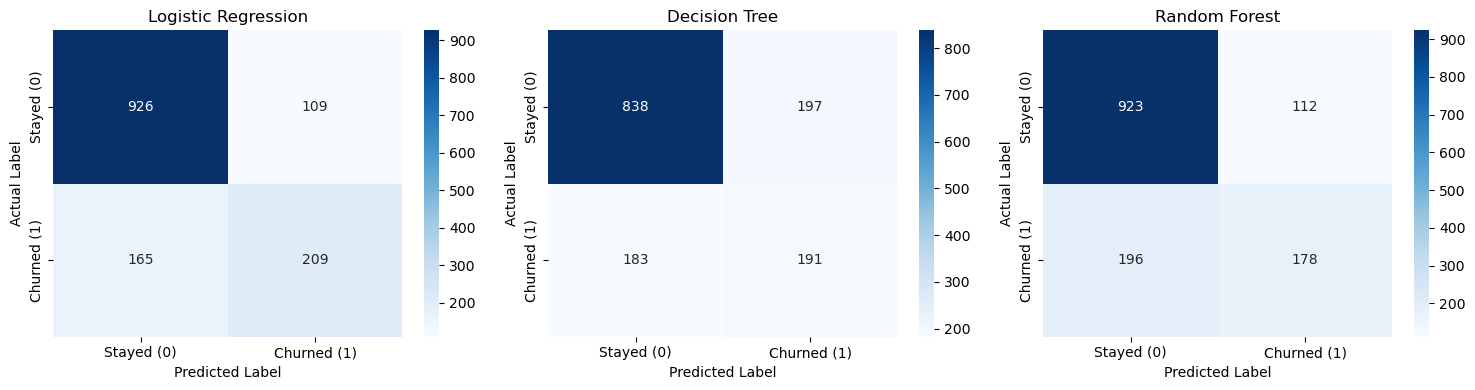

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pipeline) in zip(axes, trained_models.items()):
    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Stayed (0)", "Churned (1)"],
        yticklabels=["Stayed (0)", "Churned (1)"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

# Logistic Regression Error Analysis

In [47]:
from sklearn.metrics import classification_report

best_model = trained_models["Logistic Regression"]

y_pred = best_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Churned"]
))

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [48]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_prob = best_model.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.4, 0.5]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(
        precision_score(y_test, y_pred_threshold, zero_division=0), 4
    ))
    print("Recall:", round(
        recall_score(y_test, y_pred_threshold, zero_division=0), 4
    ))
    print("F1-score:", round(
        f1_score(y_test, y_pred_threshold, zero_division=0), 4
    ))


Threshold: 0.3
Precision: 0.5193
Recall: 0.754
F1-score: 0.615

Threshold: 0.4
Precision: 0.5695
Recall: 0.6684
F1-score: 0.615

Threshold: 0.5
Precision: 0.6572
Recall: 0.5588
F1-score: 0.604


# Validation & Final Model Selection

In [49]:
from sklearn.model_selection import train_test_split

# Split the original training data into training and validation sets
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training set:", X_train_new.shape)
print("Validation set:", X_val.shape)

Training set: (4507, 19)
Validation set: (1127, 19)


In [50]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create the pipeline
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train using only the new training set
lr_pipeline.fit(X_train_new, y_train_new)

print("Logistic Regression retrained successfully!")

Logistic Regression retrained successfully!


In [51]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Predict churn probabilities on validation data
y_val_prob = lr_pipeline.predict_proba(X_val)[:, 1]

# Compare thresholds using validation data
for threshold in [0.3, 0.4, 0.5]:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(
        precision_score(y_val, y_val_pred, zero_division=0), 4
    ))
    print("Recall:", round(
        recall_score(y_val, y_val_pred, zero_division=0), 4
    ))
    print("F1-score:", round(
        f1_score(y_val, y_val_pred, zero_division=0), 4
    ))


Threshold: 0.3
Precision: 0.5433
Recall: 0.7559
F1-score: 0.6322

Threshold: 0.4
Precision: 0.6173
Recall: 0.6689
F1-score: 0.6421

Threshold: 0.5
Precision: 0.6966
Recall: 0.5452
F1-score: 0.6116


In [52]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score
)

# Predict probabilities on the untouched test set
y_test_prob = lr_pipeline.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
selected_threshold = 0.4
y_test_pred = (y_test_prob >= selected_threshold).astype(int)

print("Selected Threshold:", selected_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Stayed", "Churned"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Selected Threshold: 0.4
Accuracy: 0.7821
ROC-AUC: 0.8424

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.87      0.82      0.85      1035
     Churned       0.58      0.67      0.62       374

    accuracy                           0.78      1409
   macro avg       0.73      0.75      0.73      1409
weighted avg       0.79      0.78      0.79      1409

Confusion Matrix:
[[851 184]
 [123 251]]
